/tmp/ipykernel_16845/4211863865.py:21: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df['is_weekend'] = df['order_timestamp'].dt.dayofweek >= 5


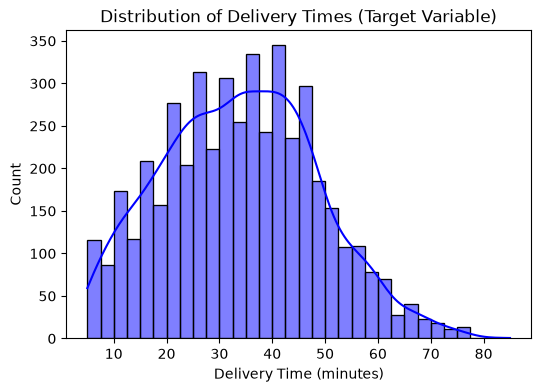

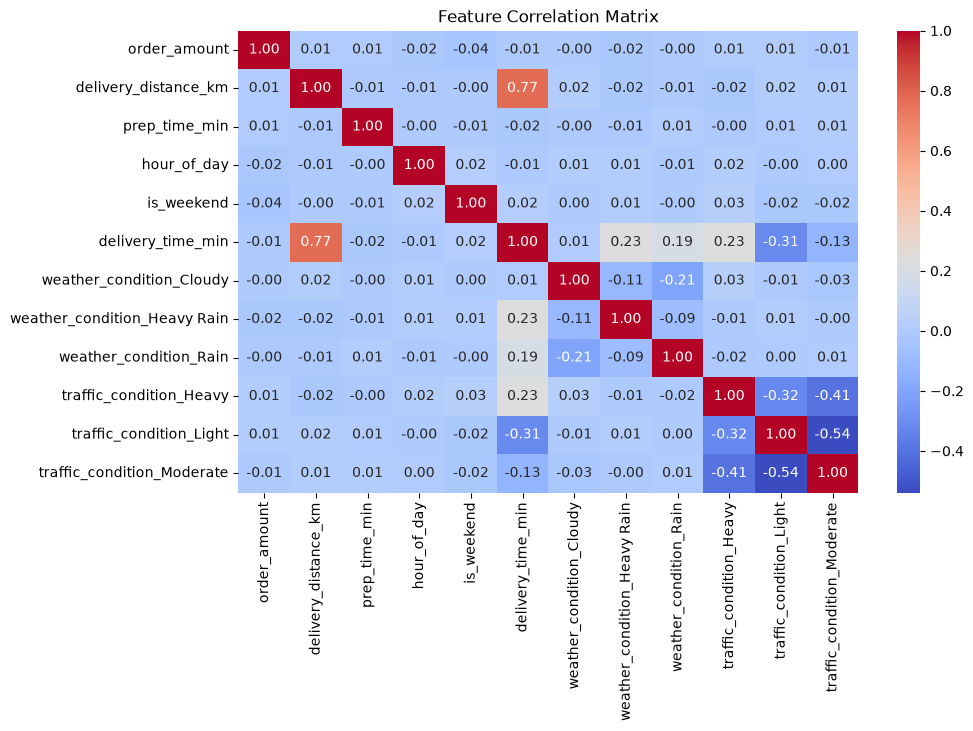

--- Model Performance Comparison ---
            Model      MAE     RMSE       R2
Baseline (Linear) 1.518163 1.931670 0.983059
 Ridge Regression 1.521784 1.935038 0.983000
    Random Forest 1.755554 2.249906 0.977017
 Lasso Regression 1.861907 2.352921 0.974864


/tmp/ipykernel_16845/4211863865.py:92: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_importance, palette='viridis')


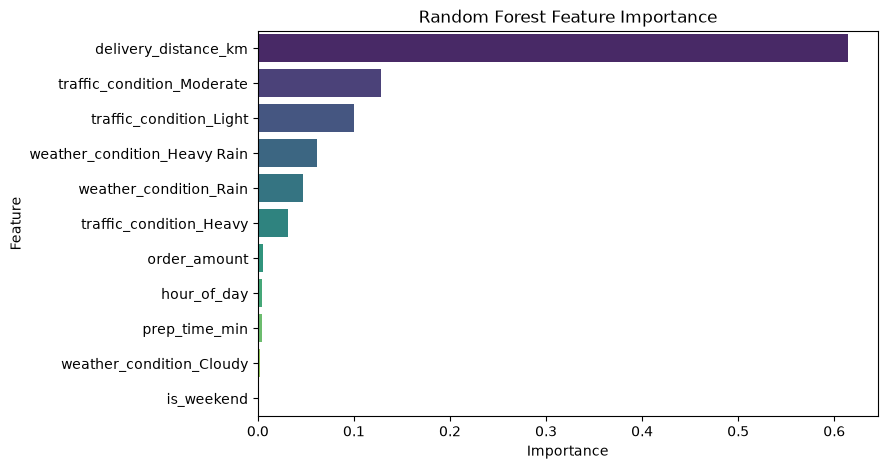

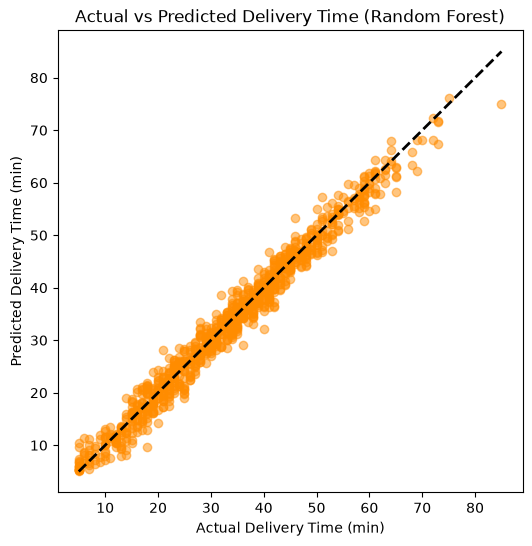

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Load & Merge Data
orders = pd.read_csv('../data/raw/orders.csv')
deliveries = pd.read_csv('../data/raw/deliveries.csv')

# Merge to get operational features and the target (delivery_time_min)
df = pd.merge(orders, deliveries, on='order_id', how='inner')

# 2. Feature Engineering
# Convert timestamp to datetime and extract temporal features
df['order_timestamp'] = pd.to_datetime(df['order_timestamp'])
df['hour_of_day'] = df['order_timestamp'].dt.hour
df['is_weekend'] = df['order_timestamp'].dt.dayofweek >= 5

# Select required columns and drop nulls
cols_to_keep = [
    'order_amount', 'delivery_distance_km', 'prep_time_min', 
    'weather_condition', 'traffic_condition', 'hour_of_day', 
    'is_weekend', 'delivery_time_min'
]
df = df[cols_to_keep].dropna()

# One-hot encode categorical variables (Weather, Traffic)
df_encoded = pd.get_dummies(df, columns=['weather_condition', 'traffic_condition'], drop_first=True)

# 3. Exploratory Data Analysis (EDA)
# Target Distribution
plt.figure(figsize=(6, 4))
sns.histplot(df_encoded['delivery_time_min'], kde=True, color='blue')
plt.title('Distribution of Delivery Times (Target Variable)')
plt.xlabel('Delivery Time (minutes)')
plt.show()

# Correlation Matrix
plt.figure(figsize=(10, 6))
sns.heatmap(df_encoded.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Feature Correlation Matrix')
plt.show()

# 4. Train-Test Split
X = df_encoded.drop(columns=['delivery_time_min'])
y = df_encoded['delivery_time_min']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 5. Model Training & Evaluation
models = {
    "Baseline (Linear)": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=0.1),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42)
}

results = []
trained_models = {}

for name, model in models.items():
    # Train
    model.fit(X_train, y_train)
    trained_models[name] = model
    
    # Predict
    y_pred = model.predict(X_test)
    
    # Metrics
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    
    results.append({'Model': name, 'MAE': mae, 'RMSE': rmse, 'R2': r2})

# Display Model Comparison
results_df = pd.DataFrame(results).sort_values(by='R2', ascending=False)
print("--- Model Performance Comparison ---")
print(results_df.to_string(index=False))

# 6. Feature Importance (from Random Forest)
rf_model = trained_models["Random Forest"]
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(x='Importance', y='Feature', data=feature_importance, palette='viridis')
plt.title('Random Forest Feature Importance')
plt.show()

# 7. Actual vs Predicted Visualization (Best Model)
# Assuming Random Forest performs best
y_pred_best = rf_model.predict(X_test)

plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred_best, alpha=0.5, color='darkorange')
plt.plot([y.min(), y.max()], [y.min(), y.max()], '--', color='black', linewidth=2)
plt.title('Actual vs Predicted Delivery Time (Random Forest)')
plt.xlabel('Actual Delivery Time (min)')
plt.ylabel('Predicted Delivery Time (min)')
plt.show()